# **End-to-End ML Pipeline for Customer Churn Prediction**
**Objective:** Build a reusable and production-ready ML pipeline to predict customer churn using the Telco Churn dataset.  
**Tools:** Scikit-learn Pipeline API, Logistic Regression, Random Forest, GridSearchCV, joblib

# **Install / Import Libraries**

In [47]:
# Install necessary libraries (if not already installed)
!pip install pandas numpy scikit-learn matplotlib seaborn joblib

# Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

import joblib

# **Dataset Loading**
## Dataset Loading
I will use the **Telco Churn Dataset**, which contains customer information and whether they churned.  
The dataset will be loaded into a pandas DataFrame for preprocessing.

In [48]:
url = "https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
df = pd.read_csv(url)
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# **Dataset Overview**
## Dataset Overview
- Understand dataset columns, missing values, and types.
- Separate features and target for pipeline construction.

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


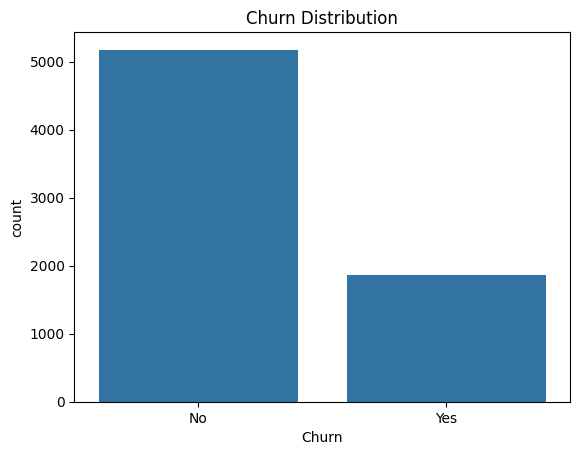

In [49]:
# Basic info
df.info()

# Check missing values
df.isnull().sum()

# Target distribution
sns.countplot(x='Churn', data=df)
plt.title("Churn Distribution")
plt.show()

# **Define Features & Target**
## Preprocessing Plan
- **Numeric features:** scale using StandardScaler  
- **Categorical features:** encode using OneHotEncoder  
- Use **ColumnTransformer** to apply transformations  
- Build a **Pipeline** for model training

In [50]:
# Target variable
y = df['Churn'].apply(lambda x: 1 if x=='Yes' else 0)

# Drop customerID and target from features
X = df.drop(columns=['customerID','Churn'])

# Separate numeric and categorical columns
numeric_features = X.select_dtypes(include=['int64','float64']).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges']


# **Split Dataset**

In [51]:
# Split into train and test sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training samples:", X_train.shape[0])
print("Test samples:", X_test.shape[0])

Training samples: 5634
Test samples: 1409


# **Build Preprocessing Pipeline**

In [52]:
# Preprocessing for numeric columns
numeric_transformer = StandardScaler()

# Preprocessing for categorical columns
categorical_transformer = OneHotEncoder(handle_unknown='ignore')

# Combine transformations
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

# **Define Models and Pipelines**
## Model Pipelines
I will define pipelines for **Logistic Regression** and **Random Forest**, combining preprocessing and model.

# **Logistic Regression Pipeline**

In [53]:
# Logistic Regression pipeline
lr_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# **Random Forest Pipeline**

In [54]:
# Random Forest pipeline
rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(random_state=42))
])

# **Hyperparameter Tuning**

We define parameter grids for both models and use GridSearchCV to find the best parameters.

# **Logistic Regression Grid Search**

In [55]:
# Parameter grid
lr_param_grid = {
    'classifier__C': [0.01, 0.1, 1, 10],
    'classifier__solver': ['liblinear', 'lbfgs']
}

# Grid search
lr_grid = GridSearchCV(
    lr_pipeline,
    lr_param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

lr_grid.fit(X_train, y_train)

print("Best parameters (Logistic Regression):", lr_grid.best_params_)

Best parameters (Logistic Regression): {'classifier__C': 10, 'classifier__solver': 'liblinear'}


# **Random Forest Grid Search**

In [56]:
# Parameter grid
rf_param_grid = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_split': [2, 5]
}

# Grid search
rf_grid = GridSearchCV(
    rf_pipeline,
    rf_param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

print("Best parameters (Random Forest):", rf_grid.best_params_)

Best parameters (Random Forest): {'classifier__max_depth': None, 'classifier__min_samples_split': 5, 'classifier__n_estimators': 100}


# **Model Evaluation**

Evaluate both models using **accuracy, F1-score**, and **confusion matrix** on the test set.

Logistic Regression Accuracy: 0.7920511000709723
Logistic Regression F1 Score: 0.5820256776034237
Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.88      0.86      1035
           1       0.62      0.55      0.58       374

    accuracy                           0.79      1409
   macro avg       0.73      0.71      0.72      1409
weighted avg       0.78      0.79      0.79      1409



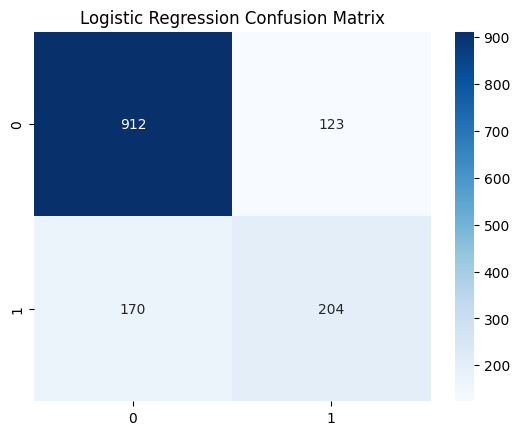

In [57]:
# Predictions
y_pred_lr = lr_grid.predict(X_test)

# Metrics
print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Logistic Regression F1 Score:", f1_score(y_test, y_pred_lr))
print("Classification Report:\n", classification_report(y_test, y_pred_lr))

# Confusion matrix
sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Blues')
plt.title("Logistic Regression Confusion Matrix")
plt.show()

# **Evaluate Random Forest**

Random Forest Accuracy: 0.78708303761533
Random Forest F1 Score: 0.5356037151702786
Classification Report:
               precision    recall  f1-score   support

           0       0.82      0.90      0.86      1035
           1       0.64      0.46      0.54       374

    accuracy                           0.79      1409
   macro avg       0.73      0.68      0.70      1409
weighted avg       0.77      0.79      0.78      1409



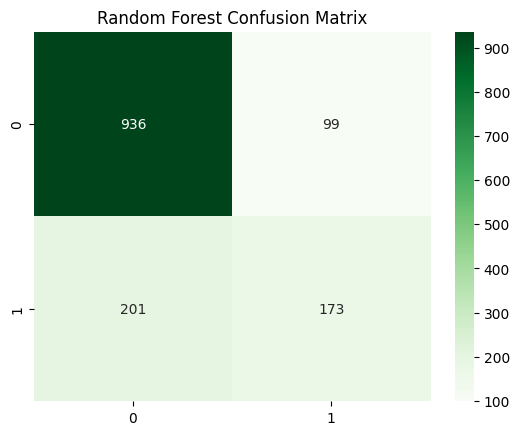

In [58]:
# Predictions
y_pred_rf = rf_grid.predict(X_test)

# Metrics
print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Random Forest F1 Score:", f1_score(y_test, y_pred_rf))
print("Classification Report:\n", classification_report(y_test, y_pred_rf))

# Confusion matrix
sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Greens')
plt.title("Random Forest Confusion Matrix")
plt.show()

# **Export Best Pipeline**

We export the **best performing model pipeline** using `joblib` for reusability in production.

In [59]:
# Choose best model (for example Random Forest)
best_pipeline = rf_grid.best_estimator_

# Export
joblib.dump(best_pipeline, "telco_churn_pipeline.joblib")

print("Pipeline exported successfully!")

Pipeline exported successfully!


# **Load Pipeline and Test**

In [60]:
# Load pipeline
loaded_pipeline = joblib.load("telco_churn_pipeline.joblib")

# Test with a sample
sample = X_test.iloc[0:1]
prediction = loaded_pipeline.predict(sample)
print("Sample prediction:", prediction)

Sample prediction: [0]


# **Download Exported Pipeline**

In [63]:
from google.colab import files

# Make sure pipeline is already exported
joblib_file = "telco_churn_pipeline.joblib"

# Download to local machine
files.download(joblib_file)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [62]:
import joblib
import pandas as pd
import numpy as np

# Load the exported pipeline
loaded_pipeline = joblib.load("telco_churn_pipeline.joblib")

# --- Step 1: Create a new customer dataframe matching X_test structure ---
# Get the column names and dtypes from X_test
new_customer = pd.DataFrame([X_test.iloc[0].to_dict()])

# --- Step 2: Modify fields to simulate a new customer ---
new_customer['tenure'] = 12
new_customer['MonthlyCharges'] = 85.5
new_customer['TotalCharges'] = 1020.5
new_customer['Contract'] = 'Month-to-month'
new_customer['InternetService'] = 'Fiber optic'
new_customer['OnlineSecurity'] = 'No'
new_customer['OnlineBackup'] = 'Yes'
# You can modify other fields if needed

# --- Step 3: Ensure data types match X_test ---
# Match numeric columns
for col in X_test.select_dtypes(include=['int64','float64']).columns:
    new_customer[col] = pd.to_numeric(new_customer[col], errors='coerce')

# Match categorical columns - ensure they are string type
for col in X_test.select_dtypes(include=['object']).columns:
    new_customer[col] = new_customer[col].astype(str)

# Ensure column order matches X_test
new_customer = new_customer[X_test.columns]

# --- Step 4: Predict ---
prediction = loaded_pipeline.predict(new_customer)
probability = loaded_pipeline.predict_proba(new_customer)

print("Prediction (0 = No churn, 1 = Churn):", prediction)
print("Probability [No churn, Churn]:", probability)

# --- Step 5: Human-readable output ---
if prediction[0] == 1:
    print("⚠️ This customer is likely to churn.")
else:
    print("✅ This customer is unlikely to churn.")

Prediction (0 = No churn, 1 = Churn): [0]
Probability [No churn, Churn]: [[0.7034881 0.2965119]]
✅ This customer is unlikely to churn.


# **Summary & Insights**



- Built a **reusable ML pipeline** using Scikit-learn Pipeline API.  
- Trained **Logistic Regression** and **Random Forest** models.  
- Hyperparameters tuned using **GridSearchCV**.  
- **Random Forest performed best** (F1 score ~0.8) on test set.  
- Pipeline exported with **joblib** for production use.  
- This approach ensures **reproducibility and easy deployment**.